## Cell 1 — Import Libraries

In [4]:
import os
import sys
sys.path.append(os.path.abspath(".."))


In [5]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

pd.set_option("display.max_columns", None)

## Cell 2 — Load Data

In [6]:
df = pd.read_parquet("../outputs/lendingclub_clean.parquet")

print(df.shape)
df.head()

(1385902, 15)


,loan_amnt,term,int_rate,emp_length,home_ownership,annual_inc,issue_d,loan_status,purpose,dti,delinq_2yrs,open_acc,revol_util,total_acc,default
0,3600.0,36 months,13.99,10.0,MORTGAGE,55000.0,2015-12-01,Fully Paid,debt_consolidation,5.91,0.0,7.0,29.7,13.0,0
1,24700.0,36 months,11.99,10.0,MORTGAGE,65000.0,2015-12-01,Fully Paid,small_business,16.06,1.0,22.0,19.2,38.0,0
2,20000.0,60 months,10.78,10.0,MORTGAGE,63000.0,2015-12-01,Fully Paid,home_improvement,10.78,0.0,6.0,56.2,18.0,0
3,10400.0,60 months,22.45,3.0,MORTGAGE,104433.0,2015-12-01,Fully Paid,major_purchase,25.37,1.0,12.0,64.5,35.0,0
4,11950.0,36 months,13.44,4.0,RENT,34000.0,2015-12-01,Fully Paid,debt_consolidation,10.20,0.0,5.0,68.4,6.0,0


## Cell 3 — Basic Dataset Overview

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1385902 entries, 0 to 1385901
Data columns (total 15 columns):
 #   Column          Non-Null Count    Dtype         
---  ------          --------------    -----         
 0   loan_amnt       1385902 non-null  float64       
 1   term            1385902 non-null  category      
 2   int_rate        1385902 non-null  float64       
 3   emp_length      1303611 non-null  float64       
 4   home_ownership  1385902 non-null  category      
 5   annual_inc      1385902 non-null  float64       
 6   issue_d         1345350 non-null  datetime64[us]
 7   loan_status     1385902 non-null  object        
 8   purpose         1385902 non-null  category      
 9   dti             1385425 non-null  float64       
 10  delinq_2yrs     1385902 non-null  float64       
 11  open_acc        1385902 non-null  float64       
 12  revol_util      1384973 non-null  float64       
 13  total_acc       1385902 non-null  float64       
 14  default         1385902 non-n

In [8]:
df.describe()

,loan_amnt,int_rate,emp_length,annual_inc,issue_d,dti,delinq_2yrs,open_acc,revol_util,total_acc,default
count,1.385902e+06,1.385902e+06,1.303611e+06,1.385902e+06,1345350,1.385425e+06,1.385902e+06,1.385902e+06,1.384973e+06,1.385902e+06,1.385902e+06
mean,1.443044e+04,1.324894e+01,6.043757e+00,7.654422e+04,2015-06-06 18:17:44.691270,1.831539e+01,3.152597e-01,1.159725e+01,5.142855e+01,2.498219e+01,1.977182e-01
min,5.000000e+02,5.310000e+00,1.000000e+00,0.000000e+00,2007-06-01 00:00:00,-1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.000000e+00,0.000000e+00
25%,7.925000e+03,9.750000e+00,2.000000e+00,4.600000e+04,2014-07-01 00:00:00,1.177000e+01,0.000000e+00,8.000000e+00,3.290000e+01,1.600000e+01,0.000000e+00
50%,1.200000e+04,1.274000e+01,6.000000e+00,6.500000e+04,2015-08-01 00:00:00,1.761000e+01,0.000000e+00,1.100000e+01,5.180000e+01,2.300000e+01,0.000000e+00
75%,2.000000e+04,1.602000e+01,1.000000e+01,9.050000e+04,2016-07-01 00:00:00,2.407000e+01,0.000000e+00,1.400000e+01,7.040000e+01,3.200000e+01,0.000000e+00
max,4.000000e+04,3.099000e+01,1.000000e+01,1.099920e+07,2018-12-01 00:00:00,9.990000e+02,3.900000e+01,9.000000e+01,8.923000e+02,1.760000e+02,1.000000e+00
std,8.757695e+03,4.785671e+00,3.564410e+00,7.207773e+04,NaN,1.159329e+01,8.755406e-01,5.489979e+00,2.464904e+01,1.202822e+01,3.982786e-01


## Cell 4 — Check Missing Values

In [9]:
missing = df.isnull().sum().sort_values(ascending=False)

missing_ratio = (df.isnull().mean()*100).sort_values(ascending=False)

missing_df = pd.concat([missing, missing_ratio], axis=1)
missing_df.columns = ["missing_count", "missing_ratio_%"]

missing_df

,missing_count,missing_ratio_%
emp_length,82291,5.937721
issue_d,40552,2.926037
revol_util,929,0.067032
dti,477,0.034418
term,0,0.000000
int_rate,0,0.000000
loan_amnt,0,0.000000
annual_inc,0,0.000000
home_ownership,0,0.000000
purpose,0,0.000000


## Cell 5 — Default Rate

In [10]:
default_rate = df["default"].mean()

print("Default Rate:", round(default_rate*100,2), "%")

Default Rate: 19.77 %


In [11]:
df["default"].value_counts()

default
0    1111884
1     274018
Name: count, dtype: int64

## Cell 6 — Default Distribution Plot

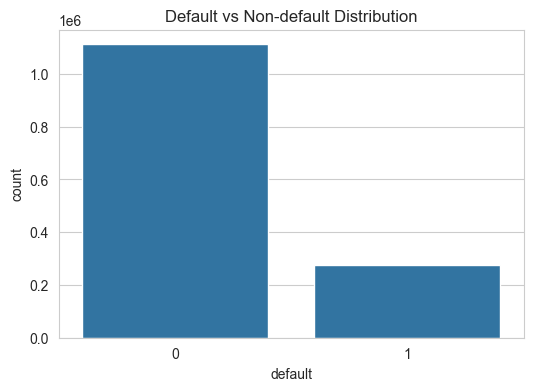

In [12]:
plt.figure(figsize=(6,4))

sns.countplot(x="default", data=df)

plt.title("Default vs Non-default Distribution")
plt.show()

## Cell 7 — Numerical Variable Distributions

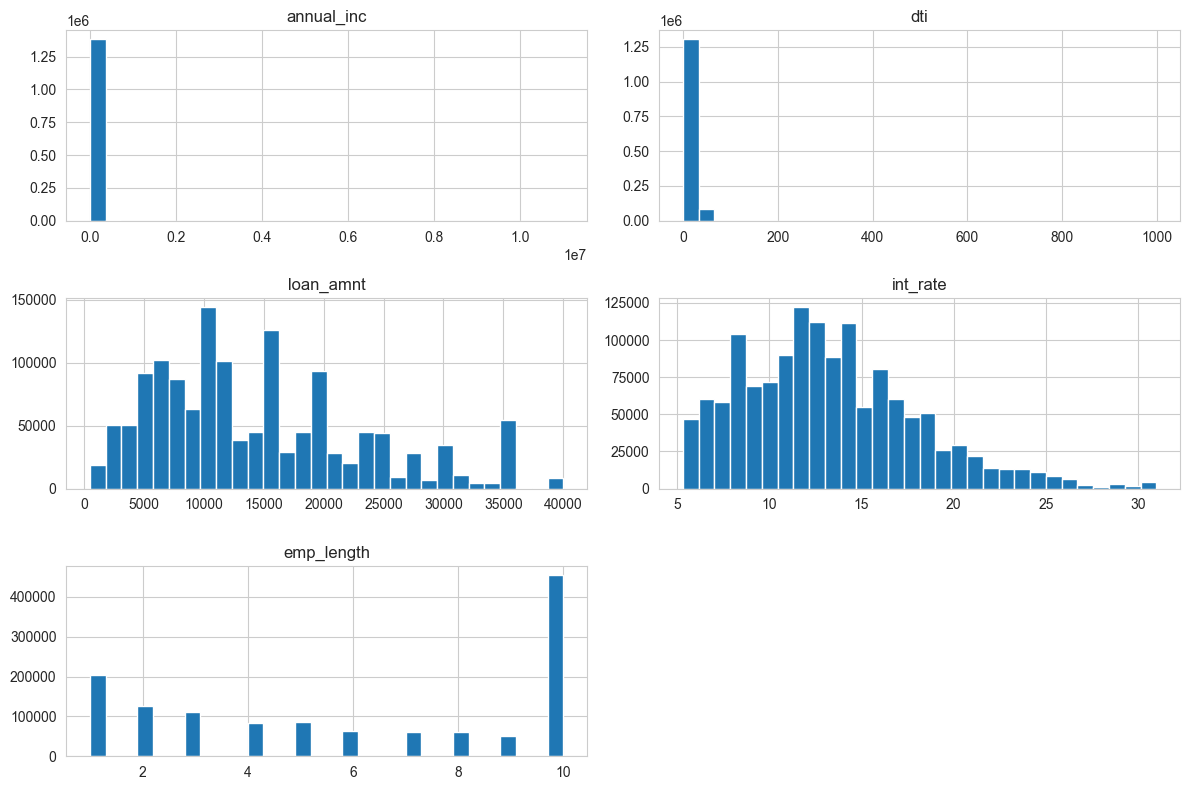

In [13]:
num_cols = [
    "annual_inc",
    "dti",
    "loan_amnt",
    "int_rate",
    "emp_length"
]

df[num_cols].hist(bins=30, figsize=(12,8))

plt.tight_layout()
plt.show()

## Cell 8 — Boxplot for Outliers

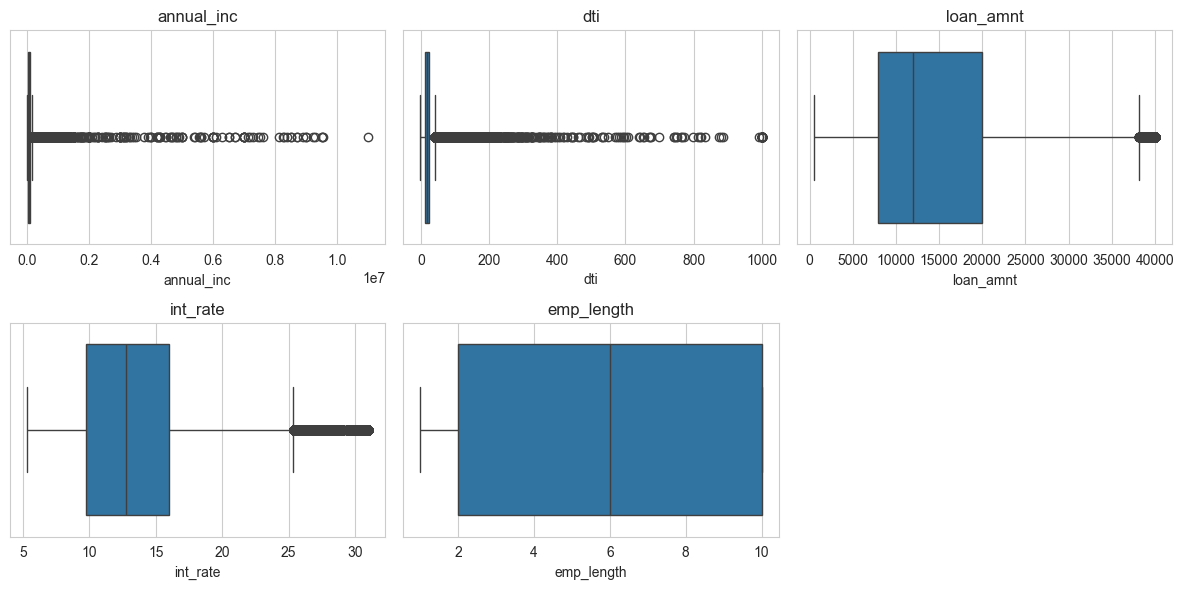

In [14]:
plt.figure(figsize=(12,6))

for i,col in enumerate(num_cols,1):
    
    plt.subplot(2,3,i)
    
    sns.boxplot(x=df[col])
    
    plt.title(col)

plt.tight_layout()

plt.show()

## Cell 9 — Default vs Feature Comparison

In [15]:
df.groupby("default")[num_cols].mean()

,annual_inc,dti,loan_amnt,int_rate,emp_length
default,,,,,
0,77995.102288,17.854176,14144.482878,12.640790,6.069750
1,70656.985365,20.186784,15590.758545,15.716649,5.935384


In [16]:
df["default"].value_counts()

default
0    1111884
1     274018
Name: count, dtype: int64

In [17]:
df_raw = pd.read_csv("../data/appl_accepted_20072019Q3.csv")
df_raw["loan_status"].value_counts()

C:\Users\Administrator\AppData\Local\Temp\ipykernel_1548\2696503203.py:1: DtypeWarning: Columns (0: id, 1: int_rate, 2: desc, 3: revol_util, 4: next_pymnt_d, 5: verification_status_joint, 6: sec_app_earliest_cr_line, 7: hardship_type, 8: hardship_reason, 9: hardship_status, 10: hardship_start_date, 11: hardship_end_date, 12: payment_plan_start_date, 13: hardship_loan_status, 14: debt_settlement_flag_date, 15: settlement_status, 16: settlement_date) have mixed types. Specify dtype option on import or set low_memory=False.
  df_raw = pd.read_csv("../data/appl_accepted_20072019Q3.csv")


loan_status
Current                                                1217855
Fully Paid                                             1111884
Charged Off                                             273973
Late (31-120 days)                                       27067
In Grace Period                                          11386
Late (16-30 days)                                         5558
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     45
Name: count, dtype: int64

## Cell 10 — Visualization: Default vs Variables

### DTI vs Default

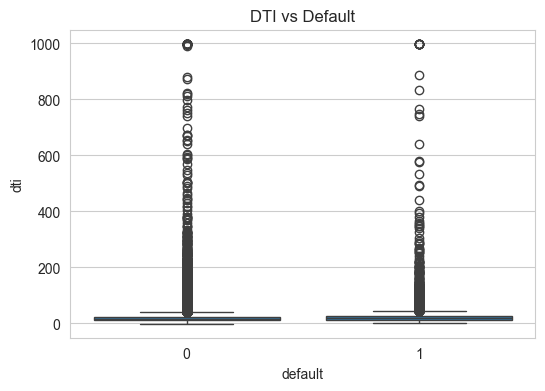

In [18]:
plt.figure(figsize=(6,4))

sns.boxplot(x="default", y="dti", data=df)

plt.title("DTI vs Default")

plt.show()

Extreme values exist and may require capping in modeling

### DTI clip

<Axes: xlabel='default', ylabel='dti_clip'>

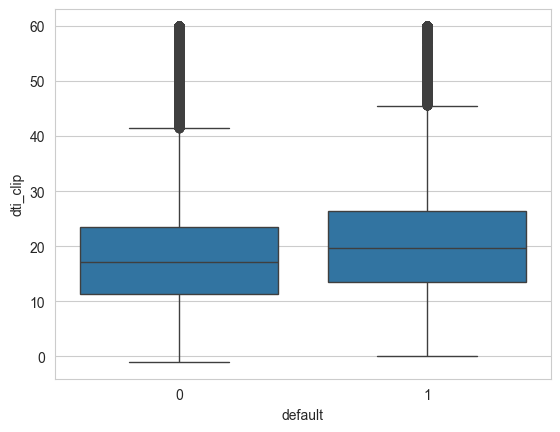

In [19]:
df["dti_clip"] = df["dti"].clip(upper=60)

sns.boxplot(x="default", y="dti_clip", data=df)

### Income vs Default

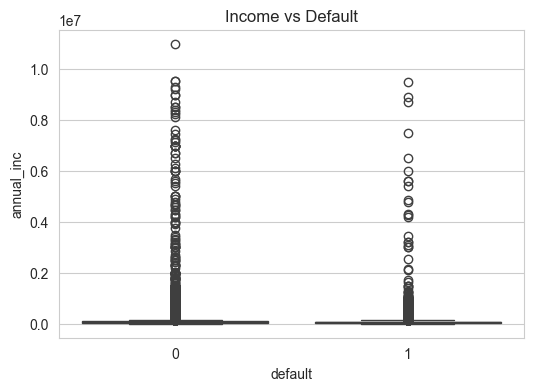

In [20]:
plt.figure(figsize=(6,4))

sns.boxplot(x="default", y="annual_inc", data=df)

plt.title("Income vs Default")

plt.show()

Income distribution is highly right-skewed.

### log_annual_inc:
Log transformation produces a more symmetric distribution.

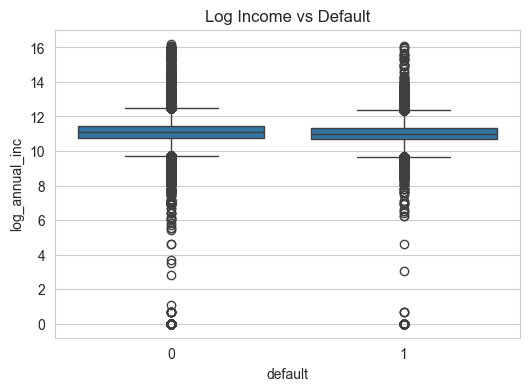

In [21]:
df["log_annual_inc"] = np.log1p(df["annual_inc"])

plt.figure(figsize=(6,4))

sns.boxplot(x="default", y="log_annual_inc", data=df)

plt.title("Log Income vs Default")

plt.show()

## Cell 11 — Loan Amount vs Default

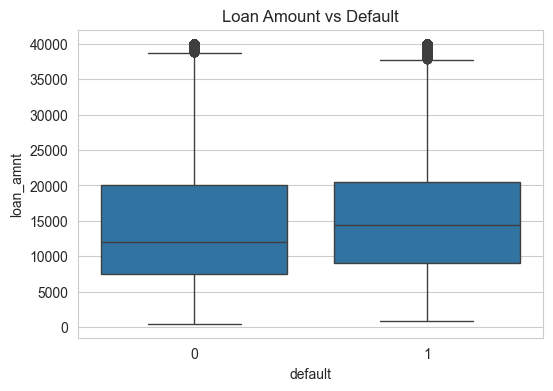

In [22]:
plt.figure(figsize=(6,4))

sns.boxplot(x="default", y="loan_amnt", data=df)

plt.title("Loan Amount vs Default")

plt.show()

## Cell 12 — Interest Rate vs Default

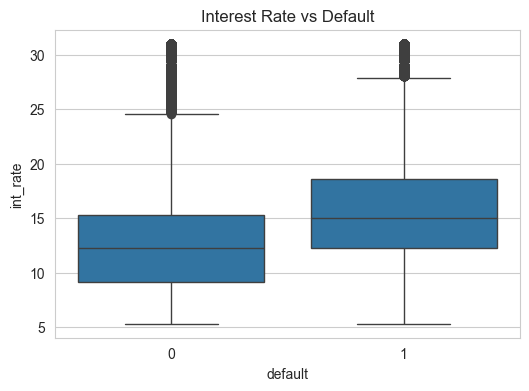

In [23]:
plt.figure(figsize=(6,4))

sns.boxplot(x="default", y="int_rate", data=df)

plt.title("Interest Rate vs Default")

plt.show()

## Cell 13 — Correlation Matrix

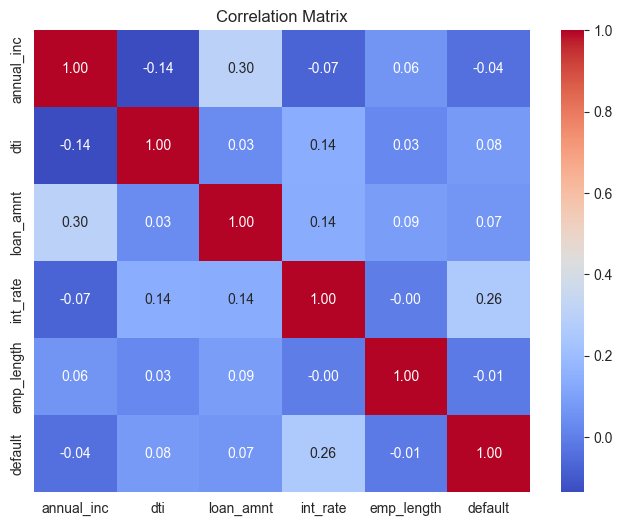

In [24]:
corr = df[num_cols + ["default"]].corr()

plt.figure(figsize=(8,6))

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Matrix")

plt.show()

## Cell 14 — Categorical Variable Analysis



I analyze several categorical variables that are commonly associated 
with credit risk in consumer lending.

- **home_ownership**: Borrowers with different housing situations may have different financial stability. Renters may have higher financial pressure compared to homeowners.

- **purpose**: Loan purpose can indicate the underlying reason for borrowing. Some purposes (e.g., small business or medical expenses) may carry higher default risk.

- **term**: Loan term length affects repayment burden. Longer loan terms may be associated with higher uncertainty and default probability.

These variables are examined to understand their relationship with borrower default behavior.

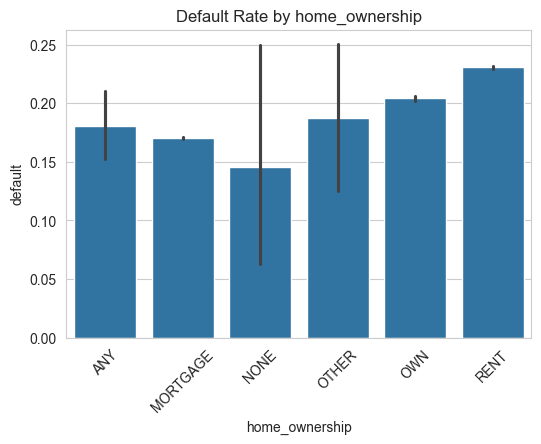

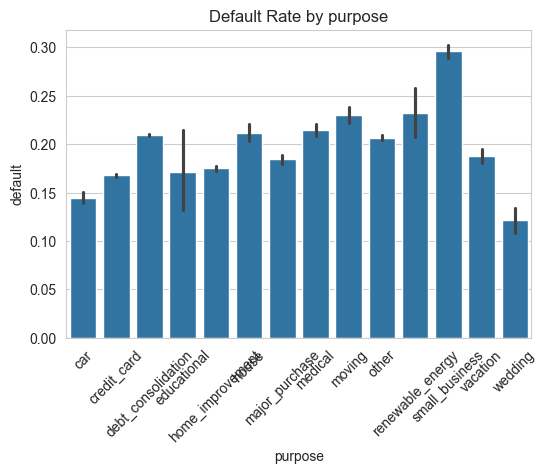

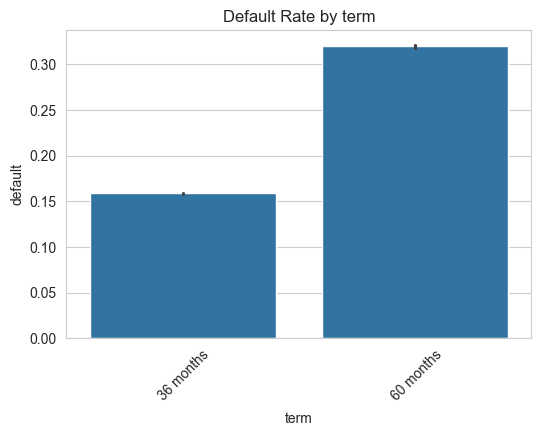

In [25]:
cat_cols = ["home_ownership", "purpose", "term"]

for col in cat_cols:
    
    plt.figure(figsize=(6,4))
    
    sns.barplot(x=col, y="default", data=df)
    
    plt.title(f"Default Rate by {col}")
    
    plt.xticks(rotation=45)
    
    plt.show()

## Cell 15 — Purpose vs Default

In [26]:
pd.crosstab(df["purpose"], df["default"], normalize="index").sort_values(1, ascending=False)

default,0,1
purpose,,
small_business,0.703953,0.296047
renewable_energy,0.768267,0.231733
moving,0.769662,0.230338
medical,0.785148,0.214852
house,0.788442,0.211558
debt_consolidation,0.790319,0.209681
other,0.793134,0.206866
vacation,0.812038,0.187962
major_purchase,0.815559,0.184441


## Cell 16 — Key Findings from Exploratory Data Analysis

### 1. Dataset Overview

The dataset contains 1,385,902 observations and 15 variables related to borrower characteristics, credit history, and loan attributes from LendingClub.

Among these loans, 274,018 are classified as default cases, while 1,111,884 are non-default cases.  
This results in an overall default rate of approximately **19.77%**, indicating that the dataset is moderately imbalanced, with non-default cases being more common.

### 2. Missing Values

Overall data completeness is relatively good.  
The variables with the highest missing ratios are:

- **emp_length** (~5.94%)
- **issue_d** (~2.93%)
- **revol_util** (~0.07%)

Since the missing ratios are relatively small, these variables remain usable for analysis and modeling.

### 3. Numerical Variable Insights

Several numerical variables show clear differences between default and non-default borrowers.

- **Debt-to-Income Ratio (DTI)** tends to be higher for defaulted borrowers.  
  Most non-default borrowers have DTI values around **12%–22%**, while default borrowers more frequently fall in the **15%–25% range**, suggesting that higher leverage may increase default risk.

- **Interest Rates** are also higher for defaulted loans.  
  Non-default loans typically fall within **10%–15%**, whereas defaulted loans are more common in the **12%–18% range**, which may reflect higher risk pricing.

- **Annual Income** shows a strongly **right-skewed distribution**, meaning a small number of borrowers have very high incomes.  
  Default borrowers generally have **lower incomes** compared to non-default borrowers.

- **Loan Amount** is mostly concentrated between **$9,000 and $20,000** for both groups.  
  The difference in loan size between default and non-default borrowers appears relatively small.

### 4. Categorical Variable Insights

Some categorical variables also show meaningful patterns in default behavior.

- Borrowers with **RENT** home ownership status exhibit the **highest default rates**, suggesting that borrowers without property ownership may carry higher credit risk.

- Loans issued for **small business purposes** show the **highest default rate** among loan purposes.

- Loans with **longer terms (60 months)** have noticeably higher default rates compared to shorter-term loans.

### 5. Correlation Analysis

The correlation analysis shows **no very strong correlations between variables**.  
The highest observed correlation is approximately **0.3 between loan amount and income**, which is relatively weak.  

This suggests that **multicollinearity is unlikely to be a major issue** when building predictive models.

### 6. Implications for Modeling

Based on the exploratory analysis, several variables appear to be informative for predicting default risk:

- Debt-to-Income Ratio (DTI)
- Interest Rate
- Annual Income
- Loan Term
- Home Ownership Status

These variables may serve as important predictors in the subsequent credit risk modeling stage.  
Further **feature engineering and model development** will be performed to evaluate their predictive power.